In [1]:
import anndata
from anndata import AnnData
import pandas as pd
import rectanglepy as rp
import matplotlib.pyplot as plt
from scipy.io import mmread
from scipy.sparse import csr_matrix
import helper

import re



# Figure 4

## Figure 4A


Load the data

In [28]:
gld = pd.read_excel("../data/fig4/luca_cancer.xlsx", index_col=0)
gld = gld.fillna(0)
gld = gld[gld["Cancer type"] == "BRCA"]

gld = gld.drop(columns=["Unnamed: 7", "Cancer type"])
gld.index = gld.index.str.replace("-", ".")
# Create a new column 'sample_name' that contains the sample names without the last character
gld['sample_name'] = gld.index.str[:-1]

# Group the rows based on the 'sample_name' column and calculate the mean for each group
df_grouped = gld.groupby('sample_name').mean()

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


### Brca data

In [5]:
annotations_brca = pd.read_csv("../data/fig4/brca_nocycling_annotations.csv", index_col=0)
sc_data_brca = pd.read_csv("../data/fig4/brca_nocycline_counts.csv", index_col=0)
bulks_brca = pd.read_csv("../data/fig4/TCGA_tpm_BRCA.txt", sep="\t")

ribsosomal_gene_re = r"^RP[SL]|^RP\d|^RPSA"
# remove ribosomal genes from bulk and scRNA-seq data
sc_data_brca = sc_data_brca[~sc_data_brca.index.str.match(ribsosomal_gene_re)]
bulks_brca = bulks_brca[~bulks_brca.index.str.match(ribsosomal_gene_re)]


annotations_brca.index = sc_data_brca.columns
annotations = pd.Series(annotations_brca["x"])

adata_brca = AnnData(sc_data_brca.T, obs=annotations.to_frame(name="cell_type"))
adata_brca = adata_brca[adata_brca.obs['cell_type'] != 'Normal Epithelial']
adata_brca_no_cancer = adata_brca[adata_brca.obs['cell_type'] != 'Cancer Epithelial']


In [ ]:
# rsults with cancer ce
brca_estimations, signature_results_brca = rp.rectangle(adata_brca, bulks_brca.T)
brca_estimations.to_csv("../output/brca_estimations.csv")


In [ ]:
brca_estimations_no_cancer, signature_results_brca_no_cancer = rp.rectangle(adata_brca_no_cancer, bulks_brca.T)
brca_estimations_no_cancer.to_csv("../output/brca_estimations_no_cancer.csv")

In [18]:
# Unknown  and Cancer Epithelial
brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Unknown'] + brca_estimations['Cancer Epithelial']
brca_estimations_m, gld_m = helper.match_dfs(brca_estimations, df_grouped)
evaluation_brca = helper.create_evaluation_df(gld_m.T, brca_estimations_m.T)
rsme_brca, r_brca, p_brca= helper.evaulate_total_df(evaluation_brca)

# Just Cancer
brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Cancer Epithelial']
brca_estimations_m, gld_m_cancer = helper.match_dfs(brca_estimations, df_grouped)
evaluation_brca_cancer = helper.create_evaluation_df(gld_m_cancer.T, brca_estimations_m.T)
rsme_brca_cancer, r_brca_cancer, p_brca = helper.evaulate_total_df(evaluation_brca_cancer)

# Just Unkwnown
brca_estimations_no_cancer = pd.read_csv("../output/brca_estimations_no_cancer.csv", index_col=0)
brca_estimations_no_cancer.index = brca_estimations_no_cancer.index.str.replace("-", ".")
brca_estimations_no_cancer['CPE'] =  brca_estimations_no_cancer['Unknown']
brca_estimations_no_cancer_m, gld_m_no_cancer = helper.match_dfs(brca_estimations_no_cancer, df_grouped)
evaluation_brca_no_cancer = helper.create_evaluation_df(gld_m_no_cancer.T, brca_estimations_no_cancer_m.T)
rsme_brca_no_cancer, r_brca_no_cancer, p_brca_no_cancer = helper.evaulate_total_df(evaluation_brca_no_cancer)

### Luad + Lusc data

In [31]:
gld = pd.read_excel("../data/fig4/luca_cancer.xlsx", index_col=0)
gld = gld.fillna(0)
gld = gld.drop(columns=["Unnamed: 7", "Cancer type"])
gld.index = gld.index.str.replace("-", ".")
# Create a new column 'sample_name' that contains the sample names without the last character
gld['sample_name'] = gld.index.str[:-1]

# Group the rows based on the 'sample_name' column and calculate the mean for each group
df_grouped = gld.groupby('sample_name').mean()


gld.to_csv("./luca_gld.csv")

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [23]:
luad_bulk = pd.read_csv("../data/fig4/luad.csv", index_col=0)
lusc_bulk = pd.read_csv("../data/fig4/lusc.csv", index_col=0)

luca_sd = anndata.read_h5ad("../data/fig4/lambrechts.h5ad")
luca_sd = luca_sd[luca_sd.obs['cell_type'] != 'Epithelial cells']
luca_sd_no_cancer = luca_sd[luca_sd.obs['cell_type'] != 'Tumor cells']

# remove ribosomal genes from bulk is enough since rectangle matches the genes
ribsosomal_gene_re = r"^RP[SL]|^RP\d|^RPSA"
luad_bulk = luad_bulk[~luad_bulk.index.str.match(ribsosomal_gene_re)]
lusc_bulk = lusc_bulk[~lusc_bulk.index.str.match(ribsosomal_gene_re)]


In [ ]:
luad_estimations, signature_results_luad = rp.rectangle(luca_sd, luad_bulk.T)
luad_estimations.to_csv("../output/luad_estimations.csv")

lusc_estimations, signature_results_lusc = rp.rectangle(luca_sd, lusc_bulk.T)
lusc_estimations.to_csv("../output/lusc_estimations.csv")

In [ ]:
luad_estimations_no_cancer, signature_results_luad_no_cancer = rp.rectangle(luca_sd_no_cancer, luad_bulk.T)
luad_estimations_no_cancer.to_csv("../output/luad_estimations_no_cancer.csv")
lusc_estimations_no_cancer, signature_results_lusc_no_cancer = rp.rectangle(luca_sd_no_cancer, lusc_bulk.T)
lusc_estimations_no_cancer.to_csv("../output/lusc_estimations_no_cancer.csv")

In [33]:
luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col=0)
luad_estimations['CPE'] = luad_estimations['Unknown'] + luad_estimations['Tumor cells']
luad_estimations_m, luad_gld_m = helper.match_dfs(luad_estimations, df_grouped)
evaluation_luad = helper.create_evaluation_df(luad_gld_m.T, luad_estimations_m.T)
rsme_luad, r_luad, p_luad = helper.evaulate_total_df(evaluation_luad)

# Just Tumor cells
luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col
=0)
luad_estimations['CPE'] = luad_estimations['Tumor cells']
luad_estimations_m, luad_gld_m_cancer = helper.match_dfs(luad_estimations, df_grouped)
evaluation_luad_cancer = helper.create_evaluation_df(luad_gld_m_cancer.T, luad_estimations_m.T)
rsme_luad_cancer, r_luad_cancer, p_luad = helper.evaulate_total_df(evaluation_luad_cancer)

# Just Unknown
luad_estimations_no_cancer = pd.read_csv("../output/luad_estimations_no_cancer.csv", index_col=0)
luad_estimations_no_cancer['CPE'] = luad_estimations_no_cancer['Unknown']
luad_estimations_no_cancer_m, luad_gld_m_no_cancer = helper.match_dfs(luad_estimations_no_cancer, df_grouped)
evaluation_luad_no_cancer = helper.create_evaluation_df(luad_gld_m_no_cancer.T, luad_estimations_no_cancer_m.T)
rsme_luad_no_cancer, r_luad_no_cancer, p_luad_no_cancer = helper.evaulate_total_df(evaluation_luad_no_cancer)

# LUSC: Unknown + Tumor cells
lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Unknown'] + lusc_estimations['Tumor cells']
lusc_estimations_m, lusc_gld_m = helper.match_dfs(lusc_estimations, df_grouped)
evaluation_lusc = helper.create_evaluation_df(lusc_gld_m.T, lusc_estimations_m.T)
rsme_lusc, r_lusc, p_lusc = helper.evaulate_total_df(evaluation_lusc)

# LUSC: Just Tumor cells
lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Tumor cells']
lusc_estimations_m, lusc_gld_m_cancer = helper.match_dfs(lusc_estimations, df_grouped)
evaluation_lusc_cancer = helper.create_evaluation_df(lusc_gld_m_cancer.T, lusc_estimations_m.T)
rsme_lusc_cancer, r_lusc_cancer, p_lusc = helper.evaulate_total_df(evaluation_lusc_cancer)

# LUSC: Just Unknown
lusc_estimations_no_cancer = pd.read_csv("../output/lusc_estimations_no_cancer.csv", index_col=0)
lusc_estimations_no_cancer['CPE'] = lusc_estimations_no_cancer['Unknown']
lusc_estimations_no_cancer_m, lusc_gld_m_no_cancer = helper.match_dfs(lusc_estimations_no_cancer, df_grouped)
evaluation_lusc_no_cancer = helper.create_evaluation_df(lusc_gld_m_no_cancer.T, lusc_estimations_no_cancer_m.T)
rsme_lusc_no_cancer, r_lusc_no_cancer, p_lusc_no_cancer = helper.evaulate_total_df(evaluation_lusc_no_cancer)





<Axes: title={'center': 'Tumor+Unkn'}, xlabel='Tumor purity', ylabel='Tumor + unknown cells'>

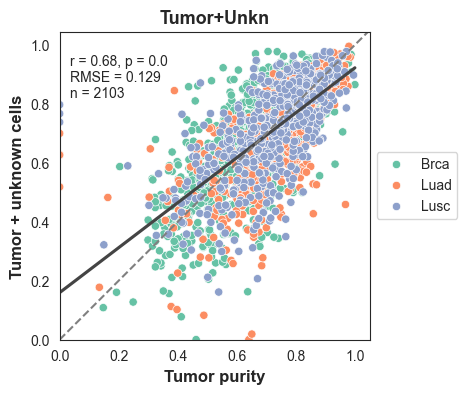

In [37]:

luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col=0)
luad_estimations['CPE'] = luad_estimations['Unknown'] + luad_estimations['Tumor cells']

lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Unknown'] + lusc_estimations['Tumor cells']

brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Unknown'] + brca_estimations['Cancer Epithelial']


luad_estimations['data'] = 'Luad'
lusc_estimations['data'] = 'Lusc'
brca_estimations['data'] = 'Brca'

all = pd.concat([brca_estimations, luad_estimations, lusc_estimations])

all_m, gld_m = helper.match_dfs(all, df_grouped)

evaluation_all = helper.create_evaluation_df(gld_m.T, all_m.T)

evaluation_all['data'] = list(all['data'])

rsme_all, r_all, p_all = helper.evaulate_total_df(evaluation_all)

helper.create_scatter_plot_total(evaluation_all, rsme_all, p_all, r_all, 'Tumor+Unkn', y_axis_label="Tumor + unknown cells", x_axis_label="Tumor purity", hue='data', save_path='../figures/fig4a_all_tumor_and_unkn_new.pdf', size=(4, 4))

<Axes: title={'center': 'Tumor'}, xlabel='Tumor purity', ylabel='Tumor cells'>

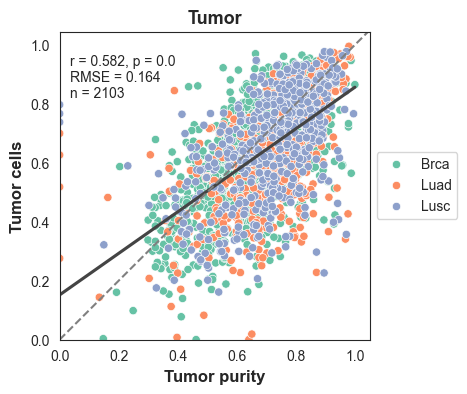

In [38]:
luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col=0)
luad_estimations['CPE'] = luad_estimations['Tumor cells']

lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Tumor cells']

brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Cancer Epithelial']

luad_estimations['data'] = 'Luad'
lusc_estimations['data'] = 'Lusc'
brca_estimations['data'] = 'Brca'

all = pd.concat([brca_estimations, luad_estimations, lusc_estimations])

all_m, gld_m = helper.match_dfs(all, df_grouped)

evaluation_all = helper.create_evaluation_df(gld_m.T, all_m.T)

evaluation_all['data'] = list(all['data'])

rsme_all_t, r_all_t, p_all = helper.evaulate_total_df(evaluation_all)

helper.create_scatter_plot_total(evaluation_all, rsme_all_t, p_all, r_all_t, 'Tumor', y_axis_label="Tumor cells", x_axis_label="Tumor purity", hue='data', save_path='../figures/fig4a_all_tumor.pdf', size=(4, 4))

<Axes: title={'center': 'Unknown'}, xlabel='Tumor purity', ylabel='Unknown cells'>

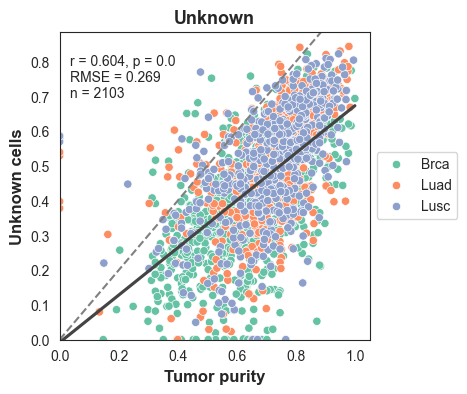

In [40]:
#no tumor
luad_estimations_no_cancer = pd.read_csv("../output/luad_estimations_no_cancer.csv", index_col=0)
luad_estimations_no_cancer['CPE'] = luad_estimations_no_cancer['Unknown']
lusc_estimations_no_cancer = pd.read_csv("../output/lusc_estimations_no_cancer.csv", index_col=0)
lusc_estimations_no_cancer['CPE'] = lusc_estimations_no_cancer['Unknown']
brca_estimations_no_cancer = pd.read_csv("../output/brca_estimations_no_cancer.csv", index_col=0)
brca_estimations_no_cancer.index = brca_estimations_no_cancer.index.str.replace("-", ".")
brca_estimations_no_cancer['CPE'] = brca_estimations_no_cancer['Unknown']

luad_estimations_no_cancer['data'] = 'Luad'
lusc_estimations_no_cancer['data'] = 'Lusc'
brca_estimations_no_cancer['data'] = 'Brca'

all_no_cancer = pd.concat([brca_estimations_no_cancer, luad_estimations_no_cancer, lusc_estimations_no_cancer])
all_no_cancer_m, gld_m_no_cancer = helper.match_dfs(all_no_cancer, df_grouped)
evaluation_all_no_cancer = helper.create_evaluation_df(gld_m_no_cancer.T, all_no_cancer_m.T)
evaluation_all_no_cancer['data'] = list(all_no_cancer['data'])
rsme_all_no_cancer, r_all_no_cancer, p_all_no_cancer = helper.evaulate_total_df(evaluation_all_no_cancer)

helper.create_scatter_plot_total(evaluation_all_no_cancer, rsme_all_no_cancer, p_all_no_cancer, r_all_no_cancer, 'Unknown', y_axis_label="Unknown cells", x_axis_label="Tumor purity", hue='data', save_path='../figures/fig4a_all_unkn.pdf', size=(4, 4))


## 4B

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Set style
sns.set_style('white')

# Data preparation
values_rsme = [rsme_brca, rsme_luad, rsme_lusc]
values_rsme_t = [rsme_brca_cancer, rsme_luad_cancer, rsme_lusc_cancer]
values_rsme_n = [rsme_brca_no_cancer, rsme_luad_no_cancer, rsme_lusc_no_cancer]

values_corr = [r_brca, r_luad, r_lusc]
values_corr_t = [r_brca_cancer, r_luad_cancer, r_lusc_cancer]
values_corr_n = [r_brca_no_cancer, r_luad_no_cancer, r_lusc_no_cancer]

# Create DataFrame
standard_df = pd.DataFrame({
    'RMSE': values_rsme,
    'Correlation': values_corr,
    'Dataset': ['Brca', 'Luad', 'Lusc'],
    'Condition': ['Tumor+Unkn'] * 3
})

tumor_df = pd.DataFrame({
    'RMSE': values_rsme_t,
    'Correlation': values_corr_t,
    'Dataset': ['Brca', 'Luad', 'Lusc'],
    'Condition': ['Tumor'] * 3
})

unknown_df = pd.DataFrame({
    'RMSE': values_rsme_n,
    'Correlation': values_corr_n,
    'Dataset': ['Brca', 'Luad', 'Lusc'],
    'Condition': ['Unkn'] * 3
})

# Concatenate the DataFrames
df = pd.concat([standard_df, tumor_df, unknown_df])



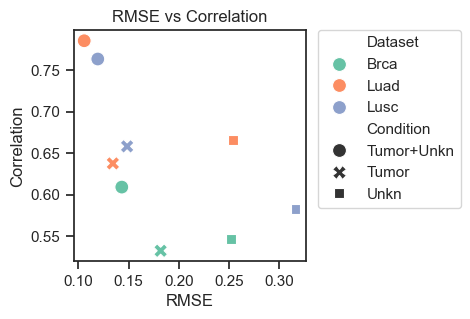

In [49]:
import seaborn as sns

import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme("notebook")
sns.set_style('ticks')
# Set a color palette
color_palette =  ['#66C2A5','#FC8D62','#8DA0CB']

# Combine the data into a single DataFrame
df_combined = pd.DataFrame({
    'RMSE': values_rsme + values_rsme_t + values_rsme_n,
    'Correlation': values_corr + values_corr_t + values_corr_n,
    'Condition': ['Tumor+Unkn'] * 3 + ['Tumor'] * 3 + ['Unkn'] * 3,
    'Dataset': ['Brca', 'Luad', 'Lusc'] * 3
})

# Create the scatter plot
plt.figure(figsize=(3, 3))
sns.scatterplot(data=df_combined, x='RMSE', y='Correlation', hue='Dataset', style='Condition', s=100,palette=color_palette)
plt.title('RMSE vs Correlation')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

# tight layout
# Save the figure
plt.savefig('../figures/fig4b_all_unkn_comparison_scatter.pdf')
plt.show()